# Detection of vehicles, their speed and type

Here I find every vehicle, measure its **speed** and **direction** and say what **type** it is (car, van, truck or tram). I use the data from `iteration3_denoising_real.ipynb`.

Steps:
1. **Hough transform** - every possible line (speed + time) gets votes from the pixels on it, the line with the most votes is the next vehicle.
2. **Region growing** - along this line, in every channel, the region of the vehicle grows in time while the image is bright. The middles of the regions are the points of the vehicle and a straight line fitted to them gives the speed and direction. The regions are removed from the image and I go back to step 1, until no line has enough votes.
3. **Classification** (thresholding) - how strong the vehicle is and how long it is: car, van, truck or tram.
4. **Speed over time** - a straight line fitted in a moving window gives the speed at every moment.
5. **Clustering** (k-means) - vehicles split into groups by their features, without any rules.

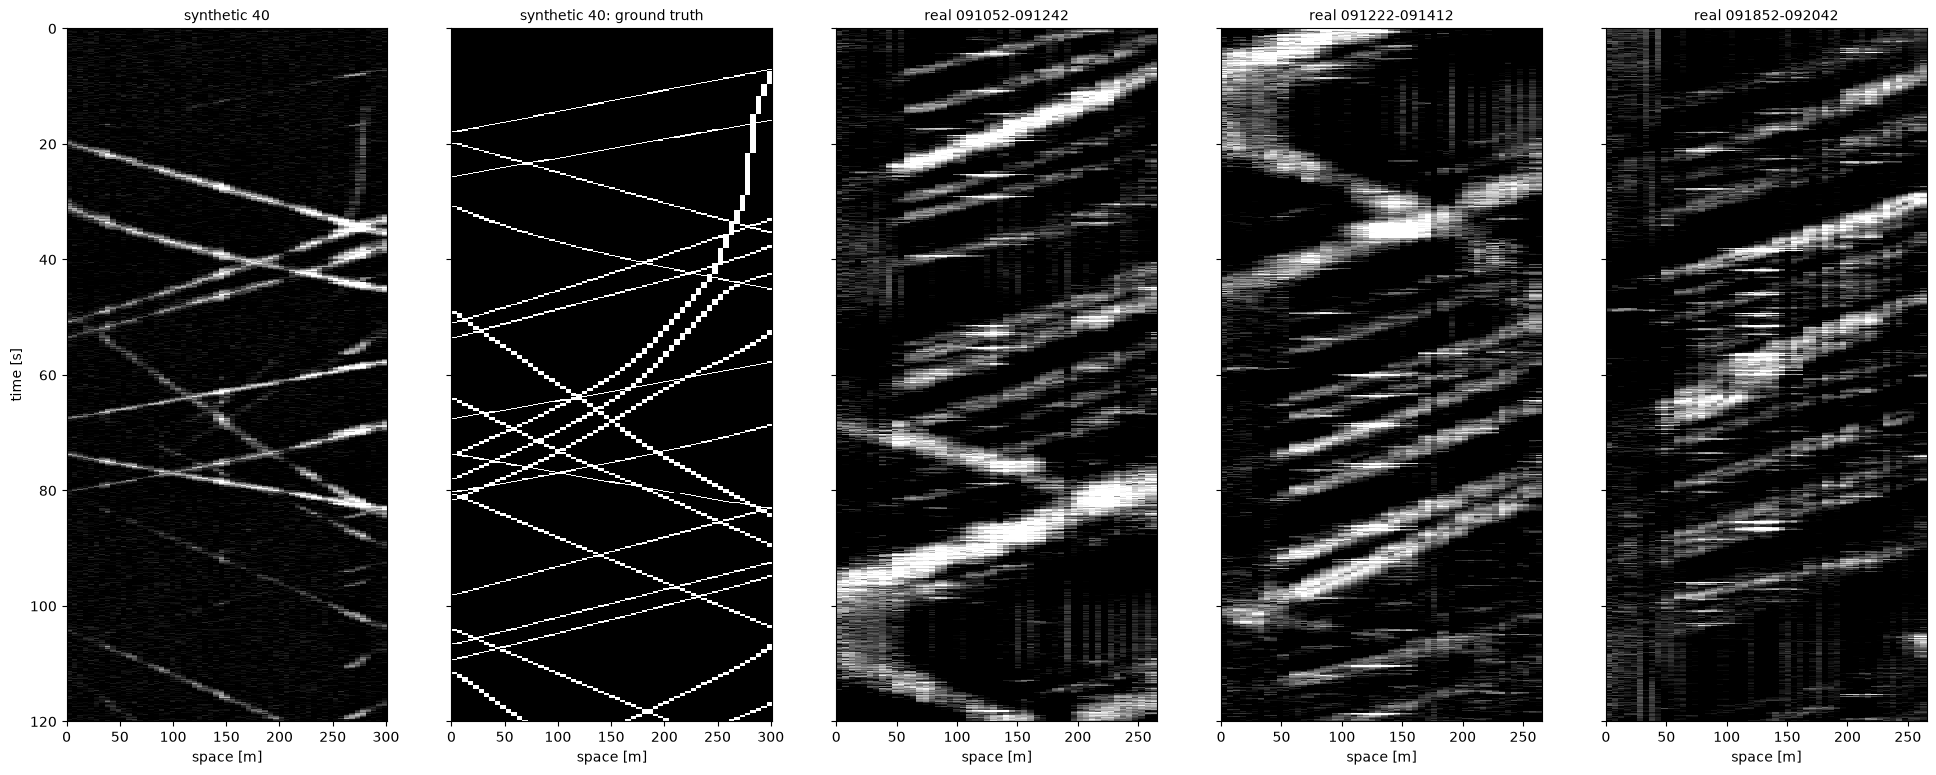

In [1]:
import os
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

import glob
import json

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DX = 5.106500953873407
DT = 0.0016
STEP = 25
DT2 = DT * STEP


def load_synthetic(i):
    vehicles = json.load(open(f'synthetic-data/{i}_metadata.json'))['ground_truth']['vehicles']
    meta = {v['marker_value']: v for v in vehicles}
    return np.load(f'images/synthetic_{i}.npy'), np.load(f'images/synthetic_{i}_ground_truth.npy'), meta


synthetic = {i: load_synthetic(i) for i in range(40, 46)}
real = {name: np.load(f'images/real_{name}.npy') for name in ['091052-091242', '091222-091412', '091852-092042']}


def show(ax, image, title, **kwargs):
    kwargs = {'cmap': 'gray', 'vmin': 0, 'vmax': 2.5, **kwargs}
    ax.imshow(image, aspect='auto', interpolation='none', extent=[0, image.shape[1] * DX, len(image) * DT2, 0], **kwargs)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('space [m]')


fig, axes = plt.subplots(1, 5, figsize=(24, 9), sharey=True)
show(axes[0], synthetic[40][0], 'synthetic 40')
show(axes[1], synthetic[40][1] > 0, 'synthetic 40: ground truth', vmax=1)
for ax, (name, image) in zip(axes[2:], real.items()):
    show(ax, image, f'real {name}')
axes[0].set_ylabel('time [s]')
plt.show()
S_demo = real['091052-091242']

## 1. Hough transform - looking for straight lines

Every vehicle is a straight line on the time vs position image. With the Hough transform I score **every possible line** (every speed and every time): the score is the mean of the image along the line, and the line with the best score is the next vehicle.

Two tricks:
- **clip at 2** - very bright pixels are cut down to 2, so a line that only crosses a big tram does not get a high score from that one spot,
- **widen by 1 row** - every pixel takes the brightest value of itself and its neighbours above and below, so a line that is slightly off still counts.

In the score chart below (Hough space) every bright spot is one vehicle: left half = vehicles going towards larger positions, right half = towards smaller positions. Crossing vehicles are two separate spots there, and gaps in a line do not matter, because the line still gets its score from the other channels. The faint "X" shapes around strong spots are lines that touch a vehicle only in a few channels, so I take only the strongest line, remove that vehicle (section 2) and score all lines again.

strongest line: speed -54 km/h, middle of the cable at 87.9 s, votes 2.00


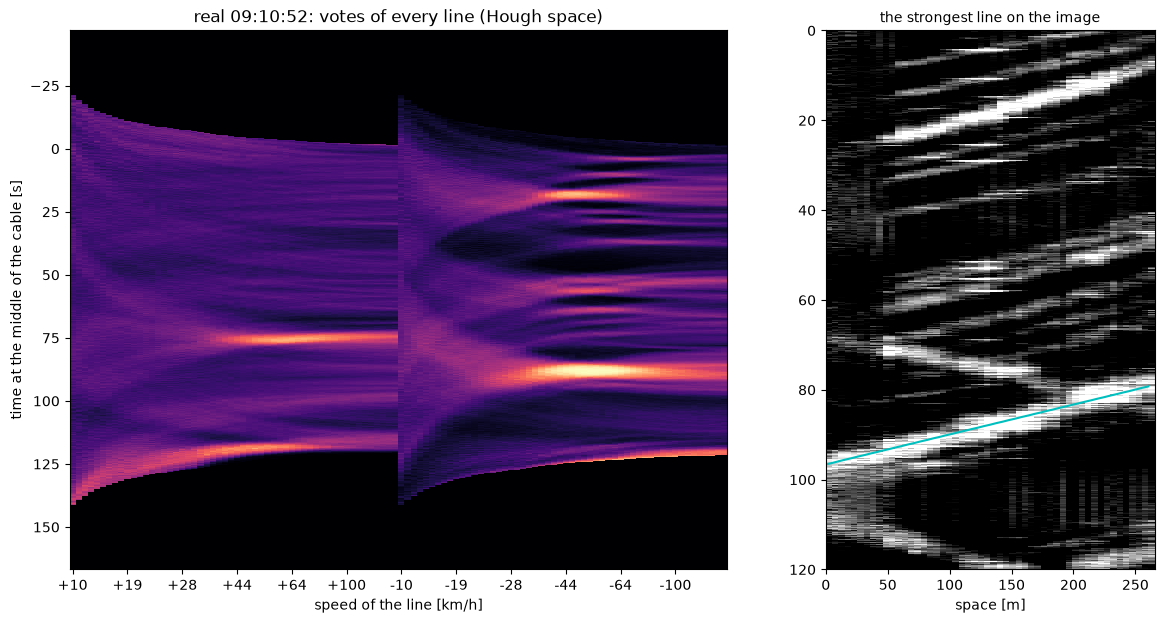

In [2]:
SPEEDS = np.r_[np.arange(10, 30, 1), np.arange(30, 60, 2), np.arange(60, 136, 4)]
SPEEDS = np.r_[SPEEDS, -SPEEDS].astype(float)


def line_rows(time_row, speed, channels):
    x = (np.arange(channels) - (channels - 1) / 2) * DX
    return np.round(time_row + 3.6 / speed * x / DT2).astype(int)


def hough(S, cap=2.0, min_channels=15):
    n, C = S.shape
    S = cv2.dilate(np.clip(S, 0, cap), np.ones((3, 1), np.uint8))
    pad = int(3.6 / 10 * (C - 1) / 2 * DX / DT2) + 1
    padded = np.full((n + 2 * pad, C), np.nan, np.float32)
    padded[pad:pad + n] = S
    rows = np.arange(-pad, n + pad)
    votes = np.zeros((len(rows), len(SPEEDS)), np.float32)
    for k, speed in enumerate(SPEEDS):
        idx = np.clip(line_rows(rows[:, None], speed, C) + pad, 0, len(padded) - 1)
        values = padded[idx, np.arange(C)]
        inside = (~np.isnan(values)).sum(axis=1)
        votes[:, k] = np.where(inside >= min_channels, np.nansum(values, axis=1) / np.maximum(inside, 1), 0)
    return votes, rows


votes, rows = hough(S_demo)
r, k = np.unravel_index(np.argmax(votes), votes.shape)
print(f'strongest line: speed {SPEEDS[k]:+.0f} km/h, middle of the cable at {rows[r] * DT2:.1f} s, votes {votes[r, k]:.2f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 7), gridspec_kw={'width_ratios': [2, 1]})
axes[0].imshow(votes, aspect='auto', interpolation='none', cmap='magma', extent=[-0.5, len(SPEEDS) - 0.5, rows[-1] * DT2, rows[0] * DT2])
ticks = np.arange(0, len(SPEEDS), 9)
axes[0].set_xticks(ticks, [f'{s:+.0f}' for s in SPEEDS[ticks]])
axes[0].set_xlabel('speed of the line [km/h]')
axes[0].set_ylabel('time at the middle of the cable [s]')
axes[0].set_title('real 09:10:52: votes of every line (Hough space)')
show(axes[1], S_demo, 'the strongest line on the image')
axes[1].plot(np.arange(S_demo.shape[1]) * DX, line_rows(rows[r], SPEEDS[k], S_demo.shape[1]) * DT2, 'c', lw=1.5)
axes[1].set_ylim(len(S_demo) * DT2, 0)
plt.show()

## 2. Region growing - points, speed and removing the vehicle

1. **Start from the Hough line.** It says roughly where the vehicle is; now I find exactly where it is in every channel.
2. **Grow a region in every channel.** In every column I start at the pixel of the line and go up and down in time as long as the image stays bright (above 0.1, i.e. a bit stronger than normal). I stop when it gets dark, or after 3 s. Before that the image is smoothed a bit (Gaussian blur, 0.2 s), so one dark pixel does not stop the growing too early.
3. **Speed and direction.** I put a straight line through the middles of the regions from all channels. Its tilt is the speed (m/s x 3.6 = km/h) and the side it leans to is the direction.
4. **Erase the vehicle.** Its regions (+ 0.8 s on both sides) are painted black, so the Hough transform does not find the same vehicle again. Then I go back to the Hough transform for the next one.
5. **When to stop.** When the best line left has a score below 0.2, there is no clear line any more. A "vehicle" seen in fewer than 8 channels is erased but not counted (probably noise).

The numbers (score 0.2, level 0.1, 0.8 s) gave the best result on the synthetic data, so the same numbers are used for real data.

first vehicle: 52 channels, speed 53.8 km/h, direction -1, shaking 6.0 s, strength 2.46


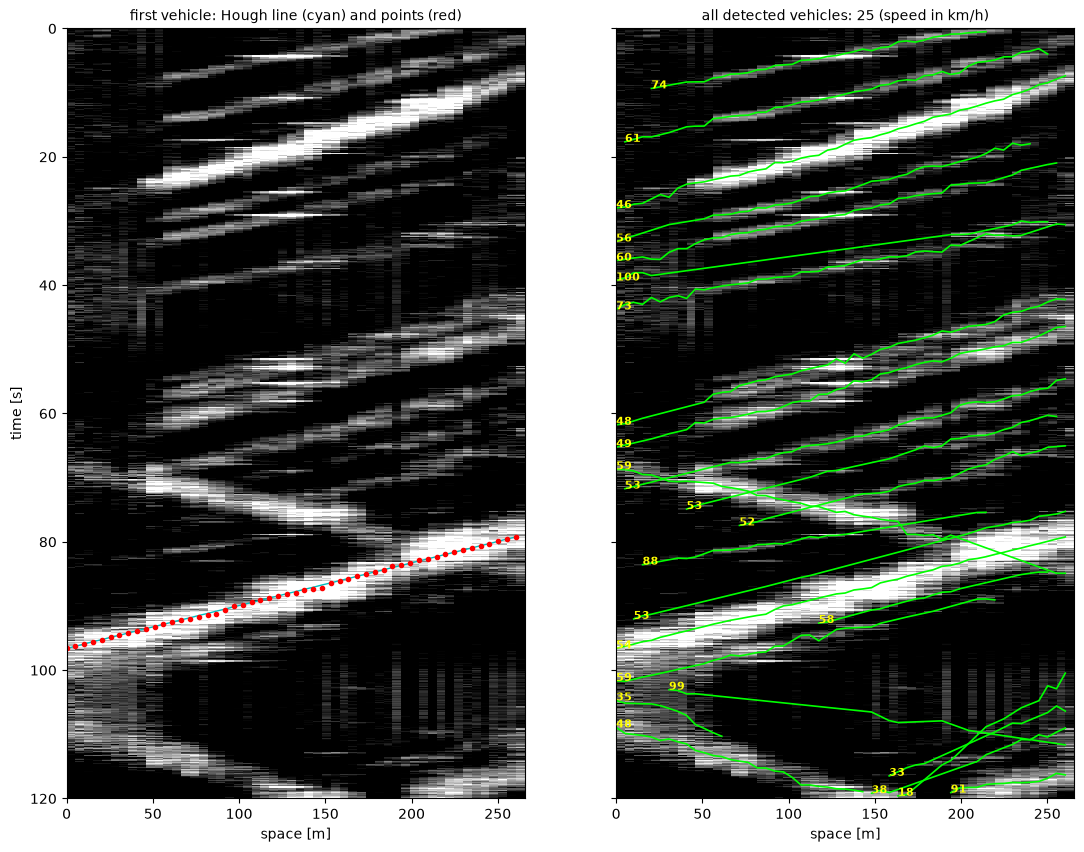

In [3]:
def grow(blurred, c, r, level=0.1, max_s=3.0):
    n = len(blurred)
    lo = hi = r
    while lo > max(r - int(max_s / DT2), 0) and blurred[lo - 1, c] > level:
        lo -= 1
    while hi < min(r + int(max_s / DT2), n - 1) and blurred[hi + 1, c] > level:
        hi += 1
    return lo, hi


def detect(S, threshold=0.2, level=0.1, margin_s=0.8, min_channels=8, max_vehicles=60):
    S = S.copy()
    n, C = S.shape
    margin = int(margin_s / DT2)
    vehicles = []
    for _ in range(max_vehicles):
        votes, rows_ = hough(S)
        r, k = np.unravel_index(np.argmax(votes), votes.shape)
        if votes[r, k] < threshold:
            break
        line = line_rows(rows_[r], SPEEDS[k], C)
        blurred = cv2.GaussianBlur(S, (1, 5), 0)
        channels, middles, shaking, strength = [], [], [], []
        for c in range(C):
            if not 0 <= line[c] < n:
                continue
            if blurred[line[c], c] > level:
                lo, hi = grow(blurred, c, line[c], level)
                channels.append(c)
                middles.append((lo + hi) / 2)
                shaking.append((hi - lo + 1) * DT2)
                strength.append(blurred[line[c], c])
                S[max(lo - margin, 0):hi + margin + 1, c] = 0
            else:
                S[max(line[c] - margin, 0):line[c] + margin + 1, c] = 0
        if len(channels) < min_channels:
            continue
        channels, middles = np.array(channels), np.array(middles)
        slope = np.polyfit(middles * DT2, channels * DX, 1)[0]
        speed = abs(slope) * 3.6
        vehicles.append({'start [s]': middles.min() * DT2, 'direction': int(np.sign(slope)), 'speed [km/h]': speed,
                         'strength': np.median(strength), 'shaking [s]': np.median(shaking),
                         'length [m]': np.median(shaking) * speed / 3.6, 'channels': channels, 'points': middles})
    return vehicles


def draw(ax, vehicles, color='lime', labels=True):
    for v in vehicles:
        ax.plot(v['channels'] * DX, v['points'] * DT2, color=color, lw=1.2)
        if labels:
            ax.text(v['channels'][0] * DX, v['points'][0] * DT2, f"{v['speed [km/h]']:.0f}", color='yellow', fontsize=8, fontweight='bold')


first = detect(S_demo, max_vehicles=1)[0]
print(f"first vehicle: {len(first['channels'])} channels, speed {first['speed [km/h]']:.1f} km/h, direction {first['direction']:+d}, "
      f"shaking {first['shaking [s]']:.1f} s, strength {first['strength']:.2f}")
vehicles_demo = detect(S_demo)

fig, axes = plt.subplots(1, 2, figsize=(13, 10), sharey=True)
show(axes[0], S_demo, 'first vehicle: Hough line (cyan) and points (red)')
axes[0].plot(np.arange(S_demo.shape[1]) * DX, line_rows(rows[r], SPEEDS[k], S_demo.shape[1]) * DT2, 'c', lw=1)
axes[0].plot(first['channels'] * DX, first['points'] * DT2, 'r.', ms=6)
show(axes[1], S_demo, f'all detected vehicles: {len(vehicles_demo)} (speed in km/h)')
draw(axes[1], vehicles_demo)
axes[0].set_ylabel('time [s]')
plt.show()

## 3. Check on all synthetic examples

This is the **evaluation**: the synthetic data has ground truth, so I can check which vehicles were found, and how good their speed is.

- **cars** - the hardest: in this image most synthetic cars are faint. Still the algorithm finds 61 of 79, with almost no false detections (6 in all 6 examples),
- **vans** - all 6 found,
- **trucks** - 1 of 2 found,
- **trams** - all 47 found.

The **speed** is almost exact: the median error is 0.73 km/h, and the **direction** is always correct.

In [4]:
def gt_positions(gt_ds, meta):
    out = {}
    for m in meta:
        r, c = np.nonzero(gt_ds == m)
        count = np.bincount(c, minlength=gt_ds.shape[1])
        t = np.full(gt_ds.shape[1], np.nan)
        t[count > 0] = np.bincount(c, weights=r, minlength=gt_ds.shape[1])[count > 0] / count[count > 0] * DT2
        if (count > 0).sum() >= 3:
            out[m] = t
    return out


def match(vehicles, positions, max_dt=0.6):
    pairs = []
    for a, v in enumerate(vehicles):
        for m, t in positions.items():
            tg = t[v['channels']]
            ok = ~np.isnan(tg)
            if ok.sum() >= 0.5 * len(v['channels']):
                dt = np.median(np.abs(tg[ok] - v['points'][ok] * DT2))
                if dt < max_dt:
                    pairs.append((dt, a, m))
    matched = {}
    for dt, a, m in sorted(pairs):
        if a not in matched and m not in matched.values():
            matched[a] = m
    return matched


def true_speed(v, t_gt):
    tg = t_gt[v['channels']]
    ok = ~np.isnan(tg)
    slope = np.polyfit(tg[ok], v['channels'][ok] * DX, 1)[0]
    return abs(slope) * 3.6, int(np.sign(slope))

,vehicles,detections,found,cars found,vans found,trucks found,trams found,extra,missed
sample,,,,,,,,,
40,22,17,16,8/14,1/1,0/0,7/7,1,6
41,18,17,17,10/10,2/2,0/1,5/5,0,1
42,20,19,18,10/12,0/0,0/0,8/8,1,2
43,24,21,21,11/14,2/2,1/1,7/7,0,3
44,30,29,26,14/18,0/0,0/0,12/12,3,4
45,20,18,17,8/11,1/1,0/0,8/8,1,3


found 115 of 134 vehicles, 6 extra detections: precision 0.950, recall 0.858, F1 0.902
direction correct: 100%
speed error: median 0.73 km/h, mean 1.79, 90% below 2.88


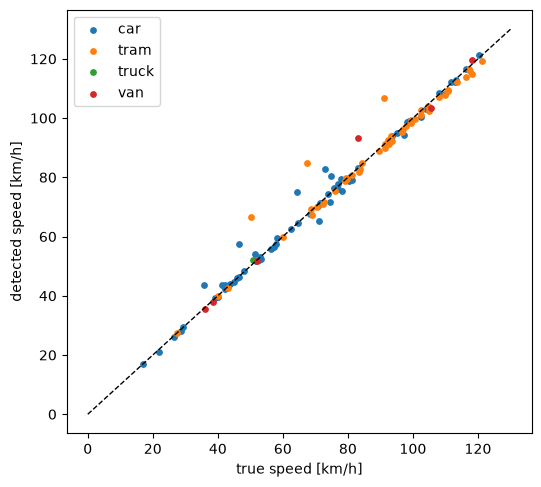

In [5]:
summary, detections, synthetic_vehicles = [], [], {}
for i, (image, gt, meta) in synthetic.items():
    positions = gt_positions(gt, meta)
    vehicles = detect(image)
    matched = match(vehicles, positions)
    synthetic_vehicles[i] = (vehicles, matched, positions)
    for a, m in matched.items():
        v = vehicles[a]
        speed, direction = true_speed(v, positions[m])
        detections.append({'sample': i, 'type': meta[m]['type'], 'true speed [km/h]': speed, 'true direction': direction,
                           **{key: v[key] for key in ['speed [km/h]', 'direction', 'strength', 'shaking [s]', 'length [m]']}})
    types = pd.Series({m: meta[m]['type'] for m in positions})
    found = set(matched.values())
    row = {'sample': i, 'vehicles': len(positions), 'detections': len(vehicles), 'found': len(found)}
    for t in ['car', 'van', 'truck', 'tram']:
        row[f'{t}s found'] = f"{sum(types[m] == t for m in found)}/{(types == t).sum()}"
    row.update({'extra': len(vehicles) - len(found), 'missed': len(positions) - len(found)})
    summary.append(row)

summary = pd.DataFrame(summary).set_index('sample')
detections = pd.DataFrame(detections)
display(summary)
total = summary[['vehicles', 'detections', 'found', 'extra', 'missed']].sum()
precision, recall = total['found'] / total['detections'], total['found'] / total['vehicles']
print(f"found {total['found']} of {total['vehicles']} vehicles, {total['extra']} extra detections: "
      f"precision {precision:.3f}, recall {recall:.3f}, F1 {2 * precision * recall / (precision + recall):.3f}")

detections['speed error [km/h]'] = (detections['speed [km/h]'] - detections['true speed [km/h]']).abs()
print(f"direction correct: {(detections['direction'] == detections['true direction']).mean():.0%}")
print(f"speed error: median {detections['speed error [km/h]'].median():.2f} km/h, mean {detections['speed error [km/h]'].mean():.2f}, "
      f"90% below {detections['speed error [km/h]'].quantile(0.9):.2f}")

fig, ax = plt.subplots(figsize=(6, 5.5))
for t, part in detections.groupby('type'):
    ax.scatter(part['true speed [km/h]'], part['speed [km/h]'], label=t, s=15)
ax.plot([0, 130], [0, 130], 'k--', lw=1)
ax.set_xlabel('true speed [km/h]')
ax.set_ylabel('detected speed [km/h]')
ax.legend()
plt.show()

**What is missed** (red dashed below): mostly cars that are almost not visible in the image, and vehicles with very **curved** lines (they stop or speed up, so no straight line fits them).

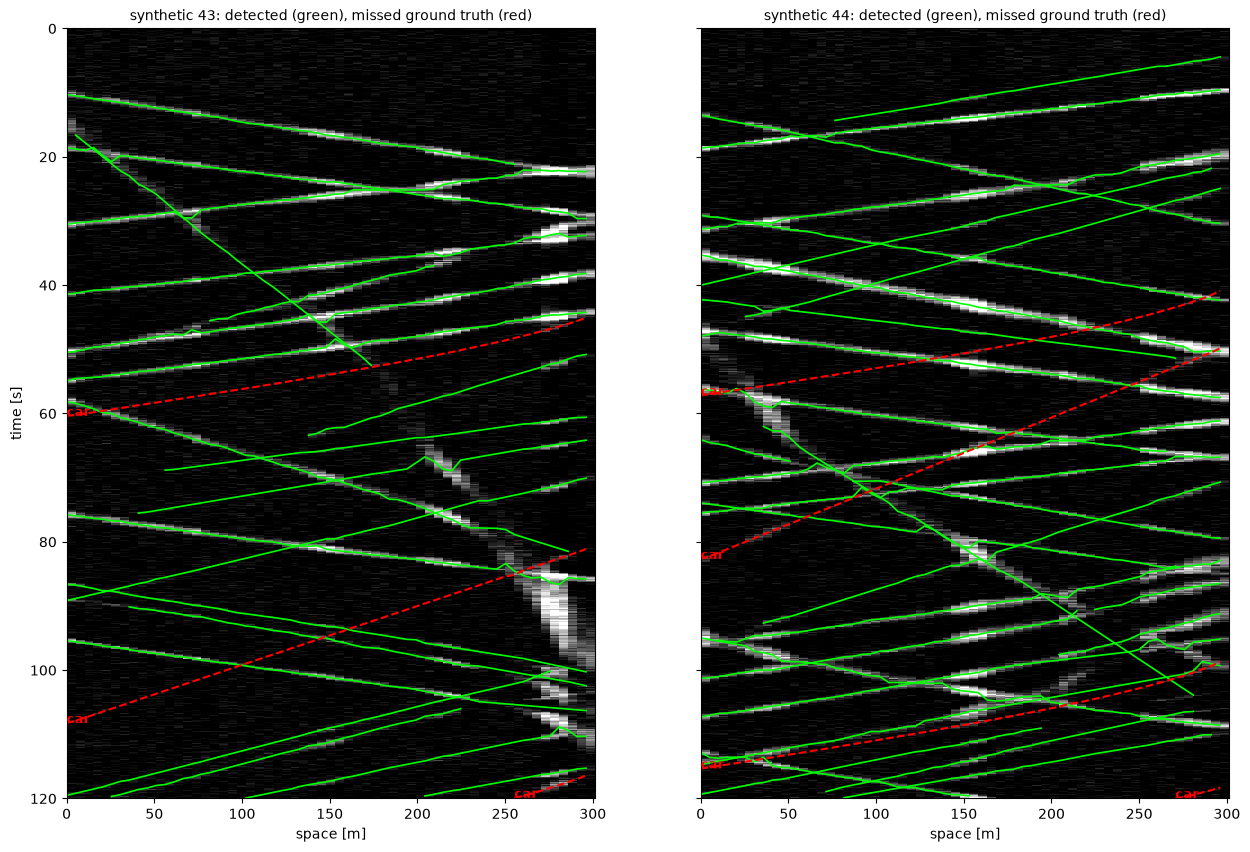

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 10), sharey=True)
for ax, i in zip(axes, [43, 44]):
    S, gt, meta = synthetic[i]
    positions = gt_positions(gt, meta)
    vehicles = detect(S)
    found = set(match(vehicles, positions).values())
    show(ax, S, f'synthetic {i}: detected (green), missed ground truth (red)')
    draw(ax, vehicles, labels=False)
    for m, t in positions.items():
        if m not in found:
            ok = ~np.isnan(t)
            ax.plot(np.nonzero(ok)[0] * DX, t[ok], 'r--', lw=1.5)
            ax.text(np.nonzero(ok)[0][0] * DX, t[ok][0], meta[m]['type'], color='red', fontsize=9, fontweight='bold')
axes[0].set_ylabel('time [s]')
plt.show()

## 4. Classification: car, van, truck or tram

Every vehicle is classified with simple rules (**strength** = how bright its line is, **length** = shaking time x speed). The rules are read **from top to bottom**: the first rule that fits gives the type.
1. strength > 1.00 **and** length > 20 m -> **tram**
2. length < 13 m -> **car**
3. length < 21 m -> **van**
4. otherwise -> **truck**

All these numbers were found on the synthetic data: 1.00 is the best strength threshold, 20 m is the shortest tram, 13 m is between the median car (11 m) and the median van (15 m), 21 m is just above the longest van.

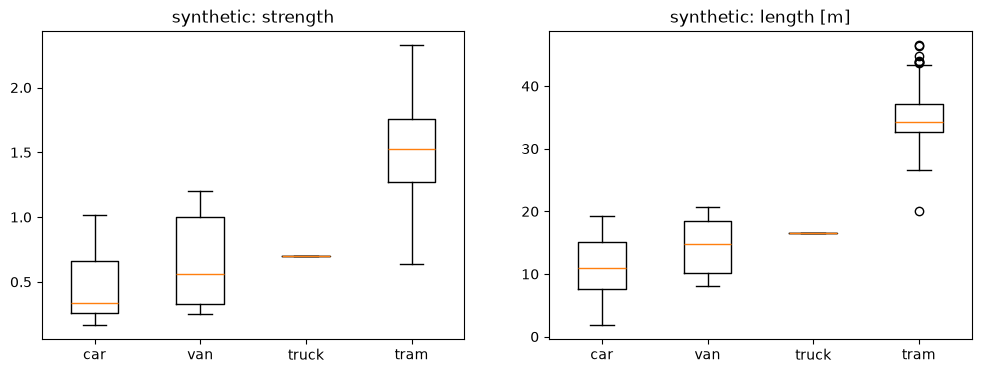

{'car': 61, 'tram': 47, 'van': 6, 'truck': 1}
strength threshold chosen on all 6 examples: 1.00


In [7]:
order = ['car', 'van', 'truck', 'tram']
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, feature in zip(axes, ['strength', 'length [m]']):
    ax.boxplot([detections.loc[detections['type'] == t, feature] for t in order], tick_labels=order)
    ax.set_title(f'synthetic: {feature}')
plt.show()
print(detections['type'].value_counts().to_dict())


CAR_VAN, VAN_TRUCK, TRAM_LENGTH = 13, 21, 20


def best_threshold(strength, is_tram):
    candidates = np.sort(strength.unique())
    accuracy = [((strength > c) == is_tram).mean() for c in candidates]
    return candidates[int(np.argmax(accuracy))]


def classify(strength, length, tram_strength):
    tram = (strength > tram_strength) & (length > TRAM_LENGTH)
    return np.where(tram, 'tram', np.where(length < CAR_VAN, 'car', np.where(length < VAN_TRUCK, 'van', 'truck')))


is_tram = detections['type'] == 'tram'
detections['class'] = ''
for i in synthetic:
    train, test = detections['sample'] != i, detections['sample'] == i
    thr = best_threshold(detections.loc[train, 'strength'], is_tram[train])
    detections.loc[test, 'class'] = classify(detections.loc[test, 'strength'], detections.loc[test, 'length [m]'], thr)
TRAM_STRENGTH = best_threshold(detections['strength'], is_tram)
print(f'strength threshold chosen on all 6 examples: {TRAM_STRENGTH:.2f}')

### Results

True type (rows) vs type given by the rules (columns), checked with leave-one-out (threshold found on 5 examples, tested on the 6th).

- **Trams** are strong and long, so they are separated well: **96.5%** tram / not tram.
- **Car / van / truck** works only partly: **77.4%** for all 4 classes. Many cars are marked as vans (their lengths overlap), and there are only 6 vans and 1 truck to learn from.

In [8]:
print(f"tram / not tram: {((detections['class'] == 'tram') == is_tram).mean():.3f}, "
      f"4 classes: {(detections['class'] == detections['type']).mean():.3f}")
display(pd.crosstab(detections['type'], detections['class'], rownames=['true'], colnames=['predicted']).reindex(index=order, columns=order, fill_value=0))

tram / not tram: 0.965, 4 classes: 0.774


predicted,car,van,truck,tram
true,,,,
car,42,19,0,0
van,2,3,0,1
truck,0,1,0,0
tram,0,1,2,44


## 5. Real data

The same detection and the same rules on the 3 real segments (the two assigned ones and our third one, 09:18:52-09:20:52). Real data has no ground truth, so the result is checked by eye: the detection looks very good - the lines follow the vehicles well and the speeds are normal for a city street (mostly 40-75 km/h).

What is on the images:
- **grey background** - the image from iteration 3 (time goes down, position along the cable goes right, brighter = stronger shaking),
- **coloured lines** - detected vehicles, drawn through their points (number detected: 09:10:52 + 09:12:22 + 09:18:52 = total):
  - **green** = car: 4 + 10 + 12 = 26
  - **yellow** = van: 3 + 4 + 7 = 14
  - **orange** = truck: 9 + 5 + 11 = 25
  - **red** = tram: 9 + 8 + 3 = 20
- **white number** at the start of every line - its speed in km/h.

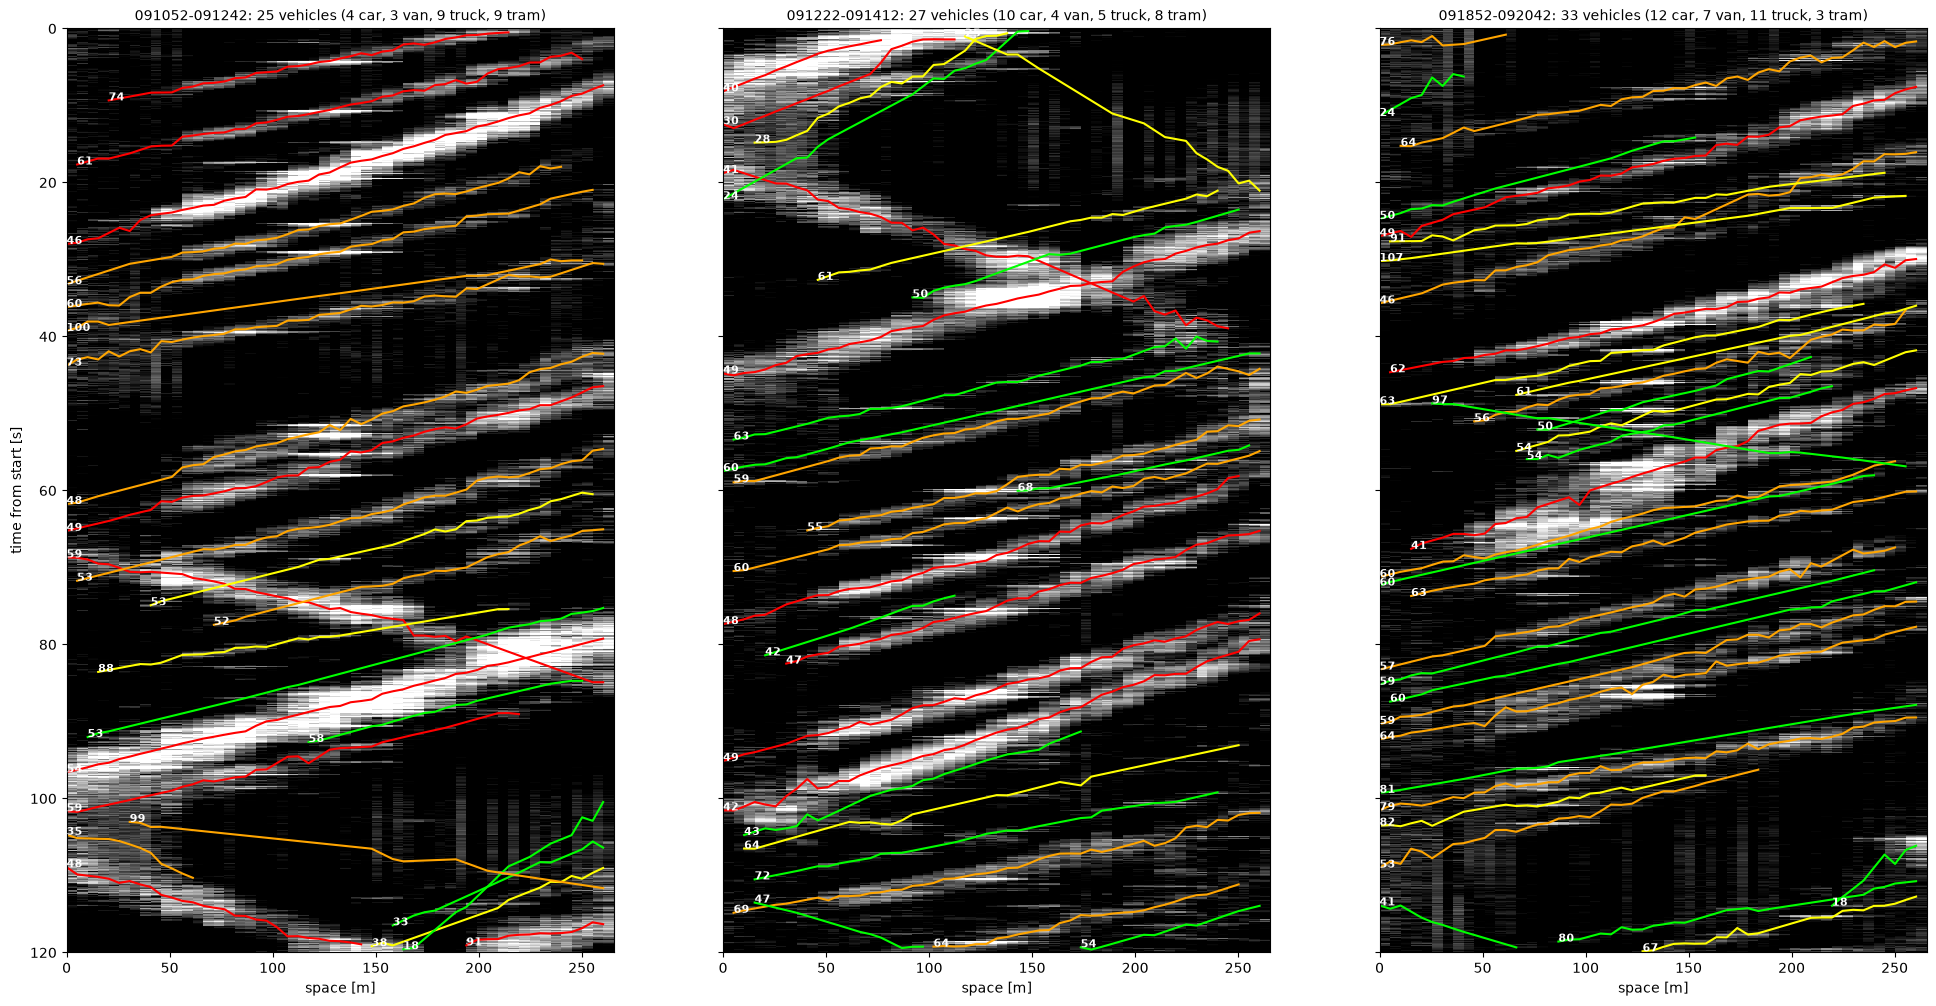

In [9]:
COLORS = {'car': 'lime', 'van': 'yellow', 'truck': 'orange', 'tram': 'red'}
real_vehicles = {}
fig, axes = plt.subplots(1, 3, figsize=(24, 12), sharey=True)
for ax, (name, S) in zip(axes, real.items()):
    vehicles = real_vehicles[name] = detect(S)
    for v in vehicles:
        v['class'] = str(classify(v['strength'], v['length [m]'], TRAM_STRENGTH))
    counts = pd.Series([v['class'] for v in vehicles]).value_counts()
    show(ax, S, f"{name}: {len(vehicles)} vehicles (" + ', '.join(f'{counts.get(t, 0)} {t}' for t in order) + ')')
    for v in vehicles:
        ax.plot(v['channels'] * DX, v['points'] * DT2, color=COLORS[v['class']], lw=1.5)
        ax.text(v['channels'][0] * DX, v['points'][0] * DT2, f"{v['speed [km/h]']:.0f}", color='white', fontsize=8, fontweight='bold')
axes[0].set_ylabel('time from start [s]')
plt.show()

## 6. Speed over time

A vehicle does not always drive at a constant speed (it brakes, starts from a stop). So instead of one straight line through all its points, I fit a straight line in a **moving window of 15 channels** (77 m) and its tilt is the speed at that moment. The sums needed for the fit are moving averages, so it is just a convolution with a box kernel (like a blur). Before that the points go through a **median filter** (5 channels), so one bad point does not make a jump, and the points in the first and last 0.5 s of the image are left out (there the vehicle is cut by the edge of the segment, so its points are wrong). Shorter windows follow the changes faster but are much noisier (7 channels: median error 4.2 km/h instead of 2.2).

On synthetic data the same is done with the ground truth, so the two curves can be compared: the **median error is 2.17 km/h** and 90% of the moments are below 11 km/h. The charts show the 3 vehicles whose speed changes the most: the detected curve follows the ground truth, but only in the part where the vehicle was found (e.g. the tram is found only after it speeds up again).

speed at every moment: median error 2.17 km/h, 90% below 11.07 km/h


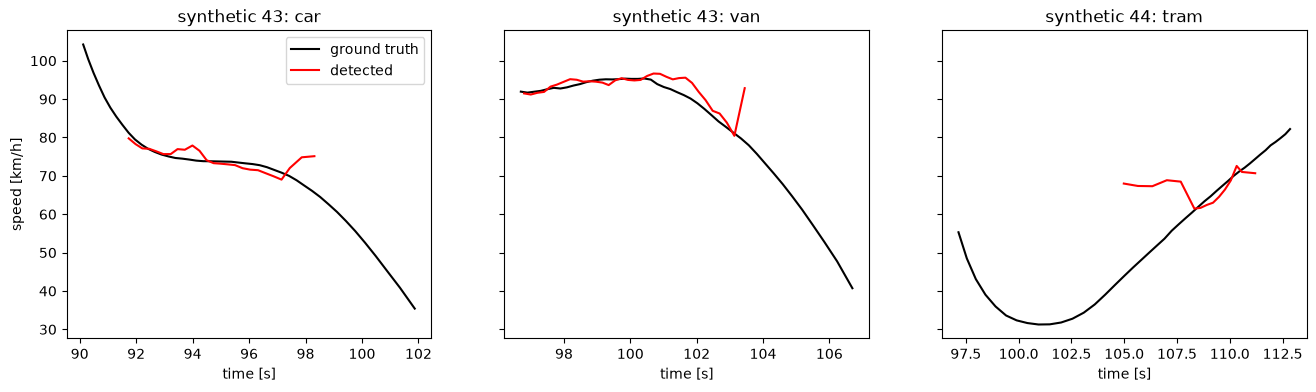

In [10]:
def speed_profile(channels, times, window=15):
    window = min(window, len(channels))
    times = cv2.medianBlur(times.astype(np.float32).reshape(-1, 1), 5).ravel().astype(float)
    box = np.ones(window) / window
    mean = lambda a: np.convolve(a, box, mode='valid')
    x = channels * DX
    t, mx = mean(times), mean(x)
    slope = (mean(times * x) - t * mx) / (mean(times * times) - t ** 2)
    order = np.argsort(t)
    return t[order], np.abs(slope[order]) * 3.6


def vehicle_profile(v, n_rows, margin_s=0.5):
    """Speed profile without the points at the top and bottom edge of the image, where the vehicle is cut."""
    keep = (v['points'] * DT2 > margin_s) & (v['points'] * DT2 < n_rows * DT2 - margin_s)
    if keep.sum() < 5:
        return np.array([]), np.array([])
    return speed_profile(v['channels'][keep], v['points'][keep] * DT2)


def speed_change(v, n_rows):
    _, speed = vehicle_profile(v, n_rows)
    return np.percentile(speed, 90) - np.percentile(speed, 10) if len(speed) else 0.0


errors, examples = [], []
for i, (vehicles, matched, positions) in synthetic_vehicles.items():
    for a, m in matched.items():
        t_gt = positions[m]
        ok = ~np.isnan(t_gt)
        t_true, v_true = speed_profile(np.nonzero(ok)[0], t_gt[ok])
        t_det, v_det = vehicle_profile(vehicles[a], len(synthetic[i][0]))
        if len(t_det) == 0:
            continue
        errors.append(np.abs(v_det - np.interp(t_det, t_true, v_true)))
        examples.append((np.ptp(v_true), i, synthetic[i][2][m]['type'], t_true, v_true, t_det, v_det))
errors = np.concatenate(errors)
print(f'speed at every moment: median error {np.median(errors):.2f} km/h, 90% below {np.percentile(errors, 90):.2f} km/h')

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, (change, i, kind, t_true, v_true, t_det, v_det) in zip(axes, sorted(examples, key=lambda e: -e[0])):
    ax.plot(t_true, v_true, 'k', label='ground truth')
    ax.plot(t_det, v_det, 'r', label='detected')
    ax.set_title(f'synthetic {i}: {kind}')
    ax.set_xlabel('time [s]')
axes[0].set_ylabel('speed [km/h]')
axes[0].legend()
plt.show()

**Real data**: every line is one vehicle (colours as in section 5). Most vehicles keep **40-70 km/h** and change their speed only by a few km/h. Bigger changes: in 09:12:22 the vehicles at 0-10 s drive only 25-40 km/h and speed up, and some vehicles speed up to 80-100 km/h at the end of the cable. Short sharp jumps come from uneven points, not from real changes.

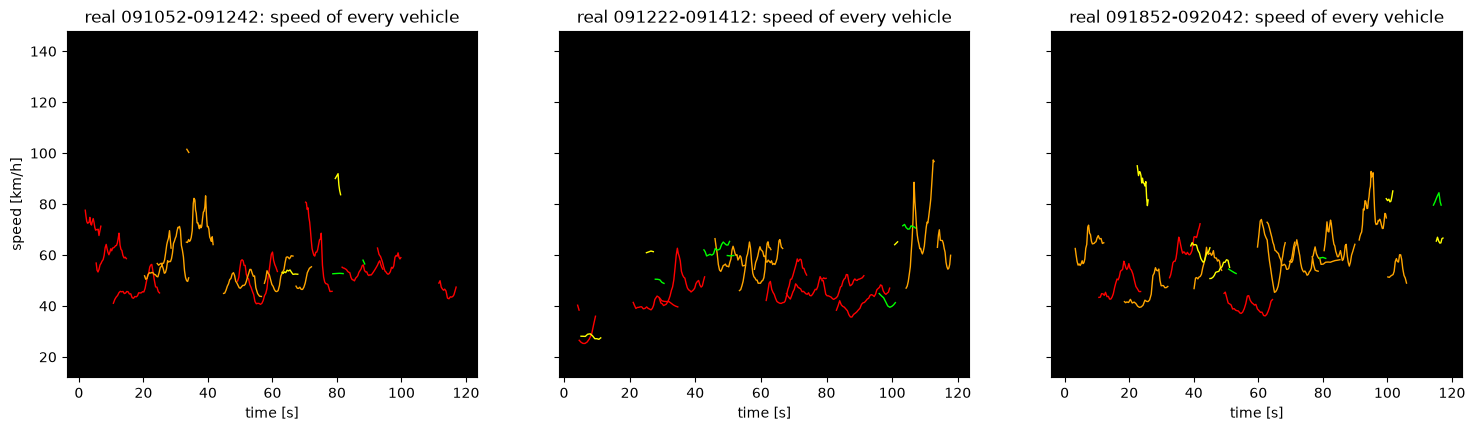

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, (name, vehicles) in zip(axes, real_vehicles.items()):
    for v in vehicles:
        ax.plot(*vehicle_profile(v, len(real[name])), color=COLORS[v['class']], lw=1)
    ax.set_facecolor('black')
    ax.set_title(f'real {name}: speed of every vehicle')
    ax.set_xlabel('time [s]')
axes[0].set_ylabel('speed [km/h]')
plt.show()

## 7. Clustering

Without rules or labels: every vehicle is described by 3 numbers - **strength** (thick or thin line), **length** and **speed change** (difference between its fastest and slowest moments, 90th - 10th percentile, so constant or varying speed). They are scaled to the same range (mean 0, std 1) and split into 4 groups with k-means (cv2.kmeans). This is done **separately** for the synthetic and the real vehicles, and in both group 0 is the weakest and group 3 the strongest, so the numbers are not the same groups.

Result on the real data (85 vehicles):
- **group 0** (cyan, 42) - thin, short lines with constant speed: probably mostly cars, but also most of the false detections (short weak lines),
- **group 1** (green, 25) - medium lines, about 33 m long,
- **group 2** (yellow, 7) - medium lines with **varying speed** (about 19 km/h between the slowest and the fastest moment),
- **group 3** (red, 11) - **thick**, long lines with constant speed: probably trams (the strongest signals, like the trams in the synthetic data).

On synthetic data (where the true types are known) the groups follow the types: group 0 holds 43 of 61 cars and no trams, and the trams are in group 3 (28) and group 2 (15). A vehicle seen in fewer than 15 channels is too short to measure its speed change, so it gets 0.

In [12]:
FEATURES = ['strength', 'length [m]', 'speed change [km/h]']


def cluster(table, k=4):
    x = table[FEATURES].to_numpy(np.float32)
    x = (x - x.mean(axis=0)) / x.std(axis=0)
    cv2.setRNGSeed(0)
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 1e-4)
    _, labels, _ = cv2.kmeans(x, k, None, criteria, 10, cv2.KMEANS_PP_CENTERS)
    labels = labels.ravel()
    weakest_first = np.argsort([table['strength'][labels == g].mean() for g in range(k)])
    return np.argsort(weakest_first)[labels]


synthetic_table = pd.DataFrame([{'type': synthetic[i][2][m]['type'], 'strength': vehicles[a]['strength'],
                                 'length [m]': vehicles[a]['length [m]'], 'speed change [km/h]': speed_change(vehicles[a], len(synthetic[i][0]))}
                                for i, (vehicles, matched, _) in synthetic_vehicles.items() for a, m in matched.items()])
synthetic_table['group'] = cluster(synthetic_table)
print('synthetic: true type vs group')
display(pd.crosstab(synthetic_table['type'], synthetic_table['group']).reindex(order, fill_value=0))

real_table = pd.DataFrame([{'segment': name, 'strength': v['strength'], 'length [m]': v['length [m]'],
                            'speed change [km/h]': speed_change(v, len(real[name])), 'speed [km/h]': v['speed [km/h]']}
                           for name, vehicles in real_vehicles.items() for v in vehicles])
real_table['group'] = cluster(real_table)
print('real: median of every group')
display(real_table.groupby('group')[FEATURES + ['speed [km/h]']].median().round(2)
        .assign(vehicles=real_table['group'].value_counts().sort_index()))

synthetic: true type vs group


group,0,1,2,3
type,,,,
car,43,18,0,0
van,3,3,0,0
truck,0,1,0,0
tram,0,4,15,28


real: median of every group


,strength,length [m],speed change [km/h],speed [km/h],vehicles
group,,,,,
0,0.43,9.59,0.00,56.03,42
1,0.70,33.29,9.77,58.55,25
2,0.96,49.99,18.58,59.57,7
3,1.66,59.95,6.60,48.18,11


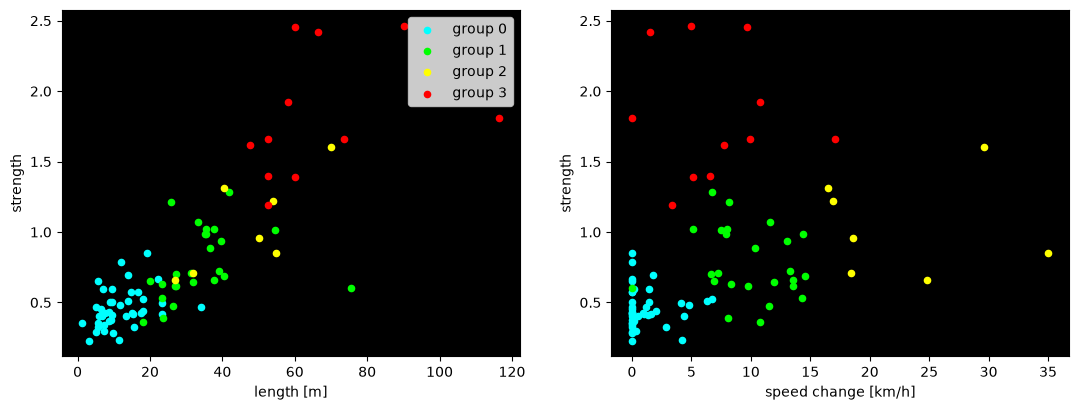

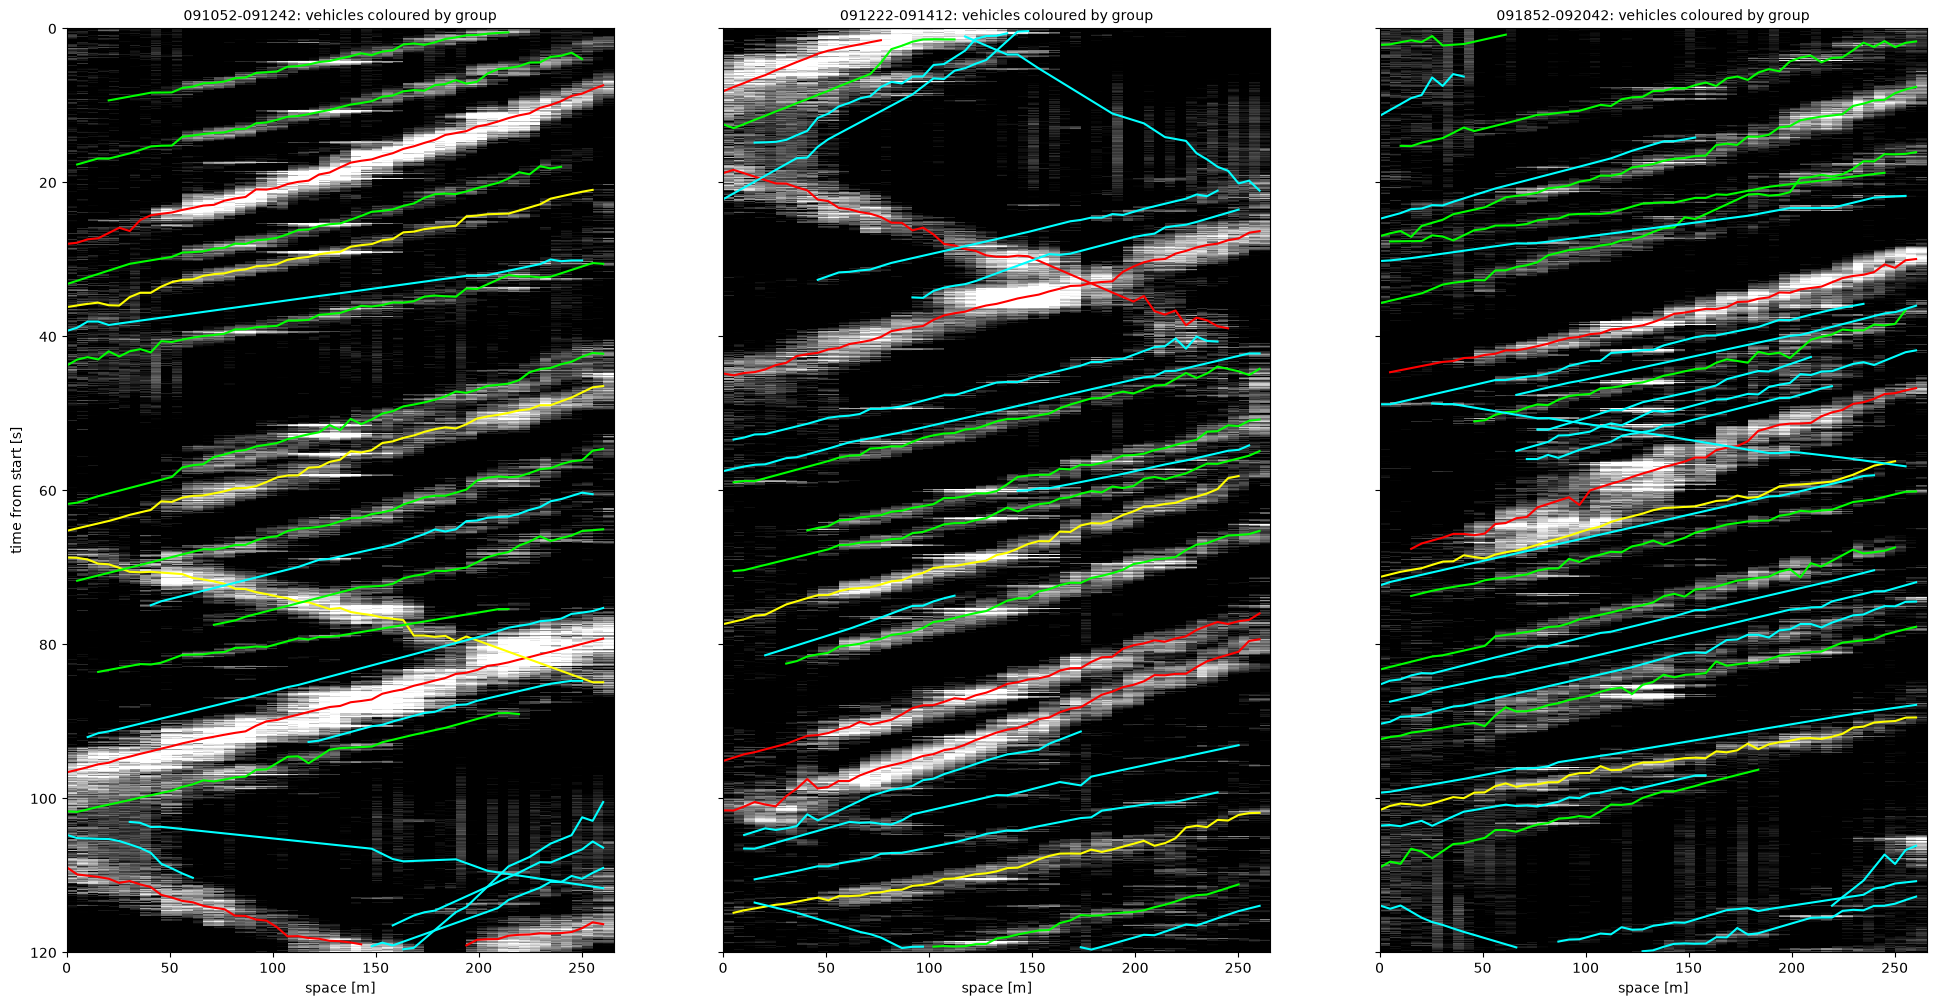

In [13]:
GROUP_COLORS = ['cyan', 'lime', 'yellow', 'red']
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for g, part in real_table.groupby('group'):
    axes[0].scatter(part['length [m]'], part['strength'], s=20, color=GROUP_COLORS[g], label=f'group {g}')
    axes[1].scatter(part['speed change [km/h]'], part['strength'], s=20, color=GROUP_COLORS[g])
axes[0].set_xlabel('length [m]')
axes[1].set_xlabel('speed change [km/h]')
for ax in axes:
    ax.set_facecolor('black')
    ax.set_ylabel('strength')
axes[0].legend()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(24, 12), sharey=True)
groups = iter(real_table['group'])
for ax, (name, S) in zip(axes, real.items()):
    show(ax, S, f'{name}: vehicles coloured by group')
    for v in real_vehicles[name]:
        ax.plot(v['channels'] * DX, v['points'] * DT2, color=GROUP_COLORS[next(groups)], lw=1.5)
axes[0].set_ylabel('time from start [s]')
plt.show()